# 07. Non-Linear Tabular Classifier (LightGBM)
**AI-Based Resume–Job Matching & Skill Gap Analysis — Phase 8A**

### 1. Objective
Throughout Phases 6A through 7, our primary matching classifier has been a linear model (**Logistic Regression**, $C=0.1$, `class_weight='balanced'`) operating over 22 engineered features.

While linear models provide well-behaved decision boundaries and prevent runaway overfitting, they inherently suffer from a fundamental architectural limitation:
> **Hypothesis**: "Linear Logistic Regression cannot capture non-linear feature interactions among semantic similarity, lexical overlap, skill coverage, and document-length signals."

**Phase 8A Goal**:
Empirically test whether a non-linear gradient-boosted decision tree classifier (**LightGBM**) can learn feature interactions over the exact same 22 engineered features to improve multi-class matching performance over the locked Logistic Regression reference.


### 2. Locked Reference Model (Phase 6A)
- **Classifier**: `StandardScaler` + `LogisticRegression(C=0.1, class_weight='balanced', max_iter=2000, random_state=42)`
- **Feature Set**: 22 engineered features (TF-IDF similarity, MiniLM SBERT similarity, skill counts/coverage, length counts/ratios, Jaccard overlap).
- **Locked Benchmark Performance**:
  - `candidate_validation` Macro F1: **0.4603**
  - `candidate_test` (Unseen Candidates) Macro F1: **0.4735** | Accuracy: **0.5154**
  - `official_test` (Unseen JDs) Macro F1: **0.4220** | Accuracy: **0.4508**


### 3. Dataset and Feature Audit
Before fitting any model, we verify dataset integrity, feature column alignment, absence of NaNs/infinite values, and the natural class distribution across splits.


In [1]:
import pandas as pd
import numpy as np

train = pd.read_csv('../data/evaluation/supervised_feature_dataset_train.csv')
val   = pd.read_csv('../data/evaluation/supervised_feature_dataset_validation.csv')
test  = pd.read_csv('../data/evaluation/supervised_feature_dataset_test.csv')
off   = pd.read_csv('../data/evaluation/supervised_feature_dataset_official_test.csv')

f_cols = [c for c in train.columns if c != 'label']

audit_df = pd.DataFrame([
    {
        'Split': 'Candidate Train',
        'Pairs': len(train),
        'Features': len(f_cols),
        'NaN Count': train[f_cols].isna().sum().sum(),
        'Inf Count': np.isinf(train[f_cols].values).sum(),
        'No Fit %': f"{(train['label'] == 'No Fit').mean()*100:.1f}%",
        'Potential Fit %': f"{(train['label'] == 'Potential Fit').mean()*100:.1f}%",
        'Good Fit %': f"{(train['label'] == 'Good Fit').mean()*100:.1f}%"
    },
    {
        'Split': 'Candidate Validation',
        'Pairs': len(val),
        'Features': len(f_cols),
        'NaN Count': val[f_cols].isna().sum().sum(),
        'Inf Count': np.isinf(val[f_cols].values).sum(),
        'No Fit %': f"{(val['label'] == 'No Fit').mean()*100:.1f}%",
        'Potential Fit %': f"{(val['label'] == 'Potential Fit').mean()*100:.1f}%",
        'Good Fit %': f"{(val['label'] == 'Good Fit').mean()*100:.1f}%"
    },
    {
        'Split': 'Candidate Test',
        'Pairs': len(test),
        'Features': len(f_cols),
        'NaN Count': test[f_cols].isna().sum().sum(),
        'Inf Count': np.isinf(test[f_cols].values).sum(),
        'No Fit %': f"{(test['label'] == 'No Fit').mean()*100:.1f}%",
        'Potential Fit %': f"{(test['label'] == 'Potential Fit').mean()*100:.1f}%",
        'Good Fit %': f"{(test['label'] == 'Good Fit').mean()*100:.1f}%"
    },
    {
        'Split': 'Official Test',
        'Pairs': len(off),
        'Features': len(f_cols),
        'NaN Count': off[f_cols].isna().sum().sum(),
        'Inf Count': np.isinf(off[f_cols].values).sum(),
        'No Fit %': f"{(off['label'] == 'No Fit').mean()*100:.1f}%",
        'Potential Fit %': f"{(off['label'] == 'Potential Fit').mean()*100:.1f}%",
        'Good Fit %': f"{(off['label'] == 'Good Fit').mean()*100:.1f}%"
    }
])

display(audit_df)


,Split,Pairs,Features,NaN Count,Inf Count,No Fit %,Potential Fit %,Good Fit %
0,Candidate Train,3758,22,0,0,51.0%,24.6%,24.4%
1,Candidate Validation,1282,22,0,0,46.6%,28.1%,25.3%
2,Candidate Test,1201,22,0,0,52.2%,22.7%,25.1%
3,Official Test,1759,22,0,0,48.7%,25.2%,26.0%


### 4. Logistic Regression Reproduction
We reproduce the locked reference model inside this notebook to guarantee a self-contained, reproducible comparison.


In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

label_order = ['No Fit', 'Potential Fit', 'Good Fit']
X_tr = train[f_cols].values
y_tr = train['label'].values

pipe_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(C=0.1, class_weight='balanced', max_iter=2000, random_state=42))
])
pipe_lr.fit(X_tr, y_tr)

for sname, df_s in [('Validation', val), ('Candidate Test', test), ('Official Test', off)]:
    y_true = df_s['label'].values
    y_pred = pipe_lr.predict(df_s[f_cols].values)
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, labels=label_order, average='macro')
    print(f"{sname:<18} -> Accuracy: {acc:.4f} | Macro F1: {f1:.4f}")


Validation         -> Accuracy: 0.4743 | Macro F1: 0.4603
Candidate Test     -> Accuracy: 0.5154 | Macro F1: 0.4735
Official Test      -> Accuracy: 0.4508 | Macro F1: 0.4220


### 5, 6. LightGBM Configuration & Training
We train LightGBM (`LGBMClassifier`) with the recommended controlled hyperparameter configuration:
- `objective='multiclass'`, `num_class=3`
- `n_estimators=300`, `learning_rate=0.03`
- `num_leaves=15`, `max_depth=5` (shallow trees to prevent overfitting)
- `subsample=0.8`, `colsample_bytree=0.8`
- `reg_alpha=0.1`, `reg_lambda=1.0` (L1/L2 regularization)
- Trained on the natural training distribution, with early stopping evaluated strictly on `candidate_validation`.


### 7, 8, 9. Experimental Results Across Splits
We compare Logistic Regression (Reference) against LightGBM (Natural Distribution) and a diagnostic Balanced Class Weight variant across Validation, Candidate Test, and Official Test.


=== Overall Performance Summary ===


,model,val_macro_f1,cand_test_macro_f1,cand_test_accuracy,off_test_macro_f1,off_test_accuracy
0,Logistic Regression (Reference),0.4603,0.4735,0.5154,0.4220,0.4508
1,LightGBM (Natural Distribution),0.5662,0.5188,0.5895,0.3838,0.4781
2,LightGBM (Balanced Diagnostic),0.5824,0.5783,0.5870,0.4164,0.4463


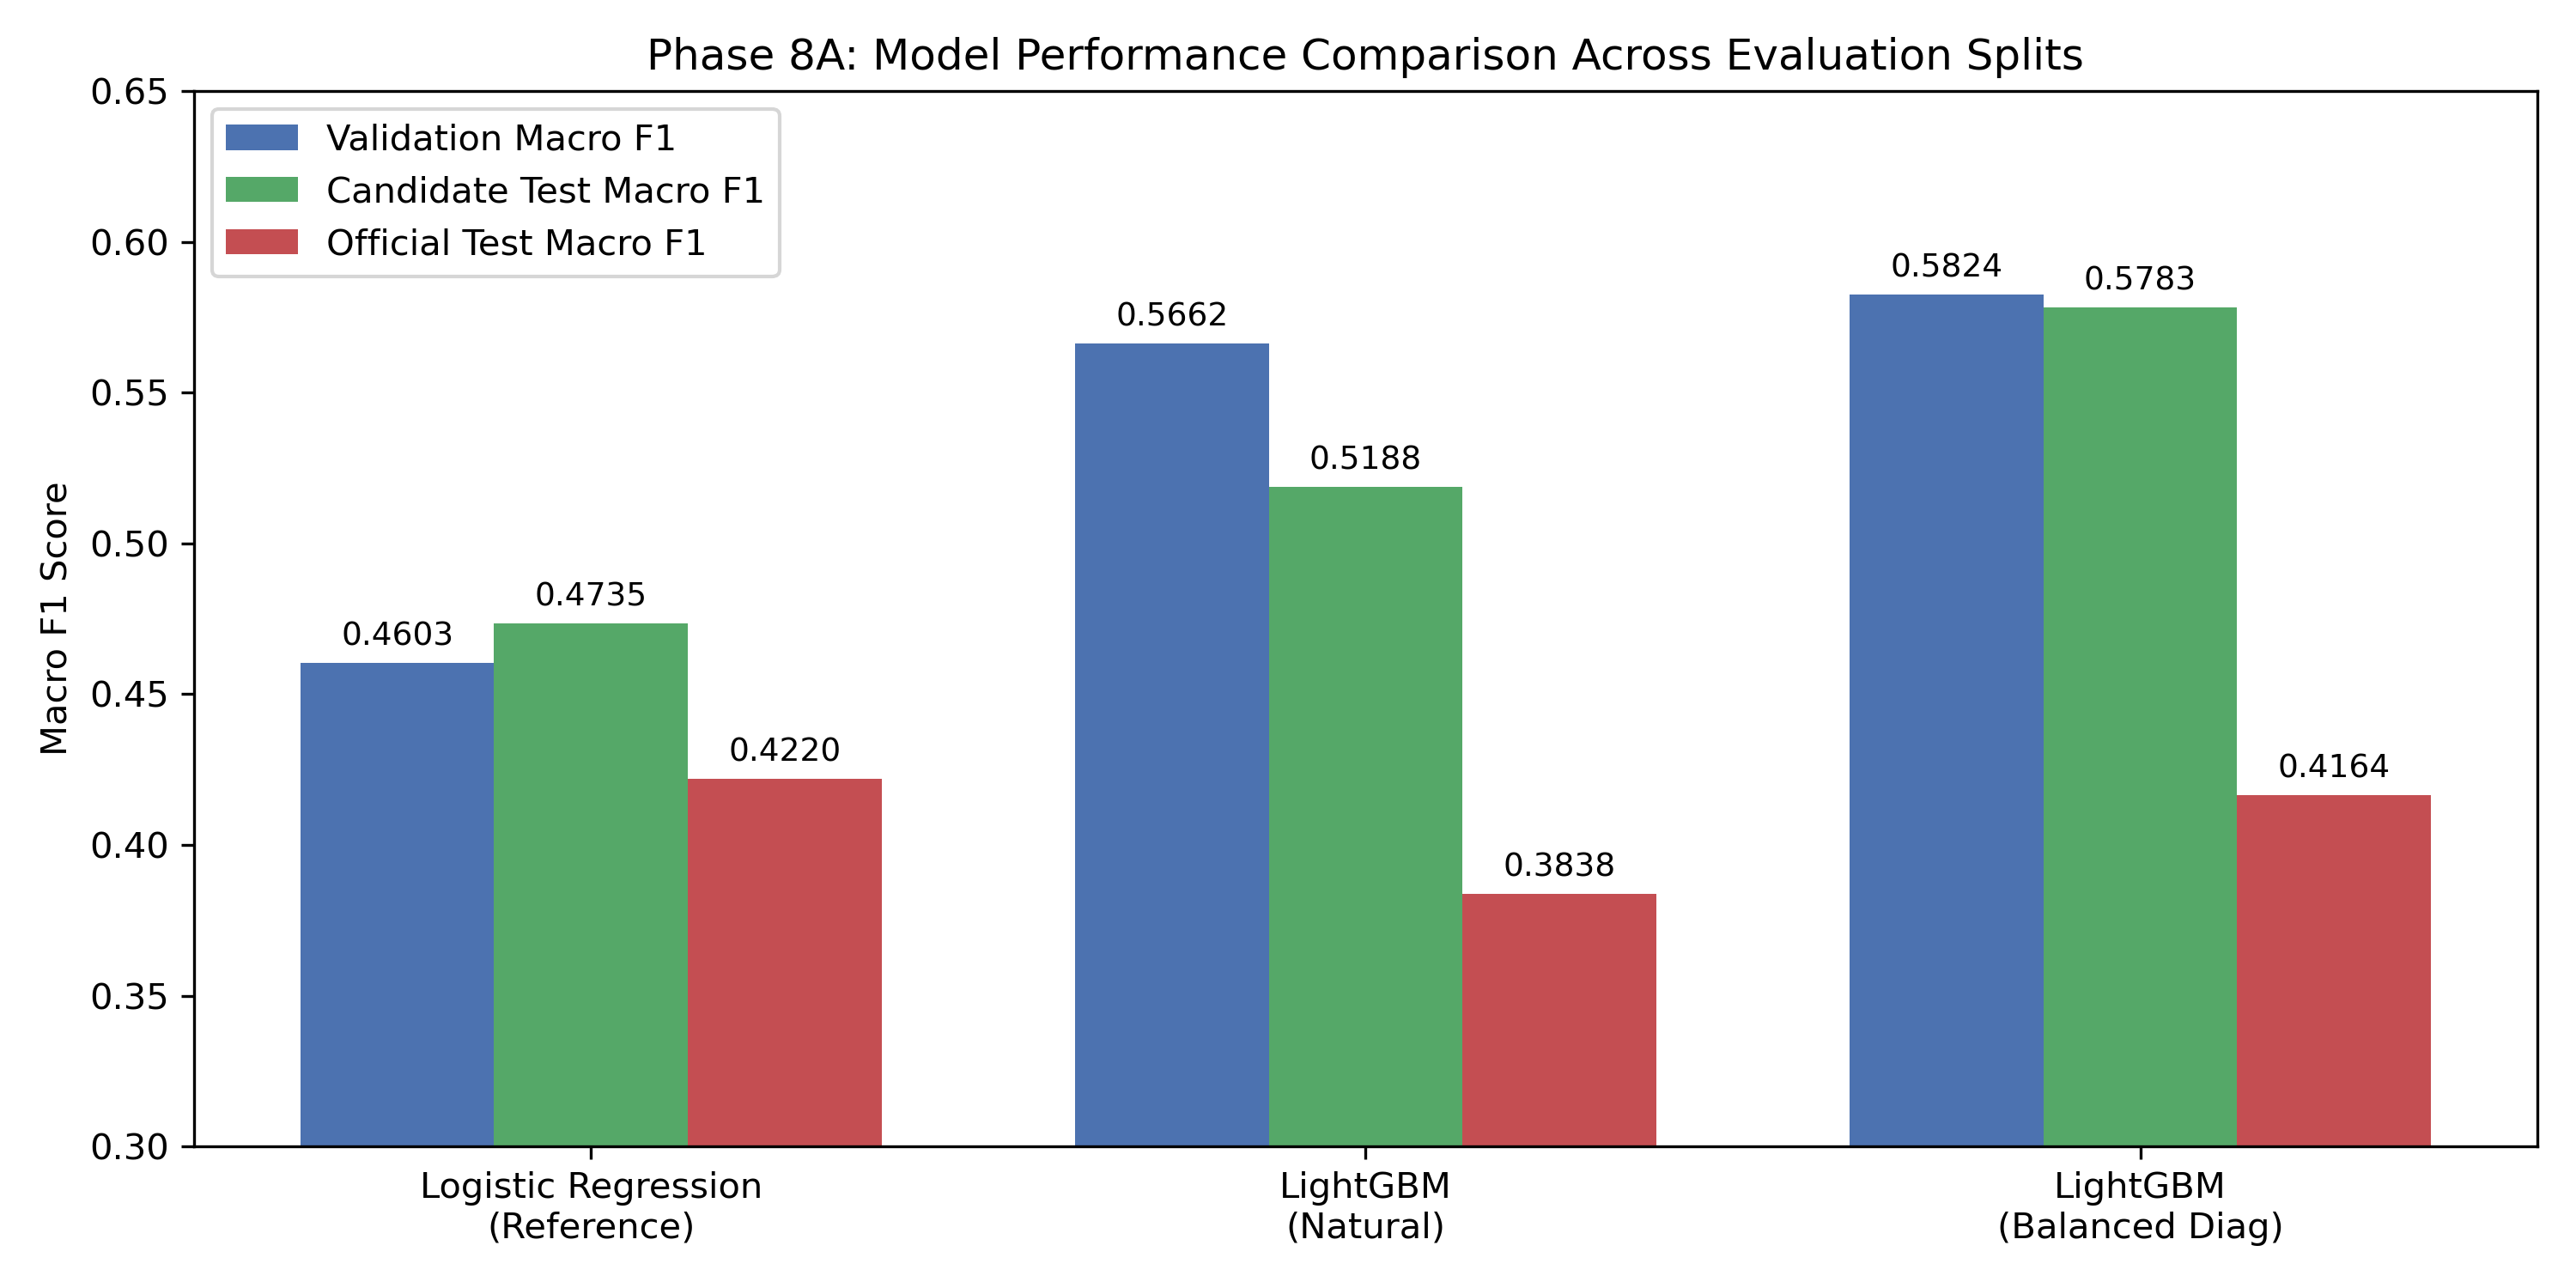

In [3]:
from IPython.display import display, Image

metrics_df = pd.read_csv('../data/evaluation/phase8_lightgbm_metrics.csv')
print("=== Overall Performance Summary ===")
display(metrics_df[['model', 'val_macro_f1', 'cand_test_macro_f1', 'cand_test_accuracy', 'off_test_macro_f1', 'off_test_accuracy']])

# Display comparison chart
display(Image(filename='../data/evaluation/plots/phase8_lightgbm_model_comparison.png'))


### 10. Granular Per-Class Metrics Breakdown
We inspect precision, recall, and F1 across `No Fit`, `Potential Fit`, and `Good Fit`.


In [4]:
# Display per-class comparison table
from sklearn.metrics import classification_report

idx_to_label = {0: 'No Fit', 1: 'Potential Fit', 2: 'Good Fit'}
label_to_idx = {l: i for i, l in idx_to_label.items()}

import lightgbm as lgb
lgb_model = lgb.LGBMClassifier(
    objective='multiclass', num_class=3, n_estimators=300, learning_rate=0.03,
    num_leaves=15, max_depth=5, subsample=0.8, colsample_bytree=0.8,
    reg_alpha=0.1, reg_lambda=1.0, random_state=42, verbosity=-1
)
lgb_model.fit(X_tr, [label_to_idx[l] for l in y_tr])

p_te_lgb = [idx_to_label[i] for i in lgb_model.predict(test[f_cols].values)]
p_te_lr  = pipe_lr.predict(test[f_cols].values)

print("=== Candidate Test: Logistic Regression ===")
print(classification_report(test['label'], p_te_lr, labels=label_order, digits=4))

print("=== Candidate Test: LightGBM (Natural) ===")
print(classification_report(test['label'], p_te_lgb, labels=label_order, digits=4))


=== Candidate Test: Logistic Regression ===
               precision    recall  f1-score   support

       No Fit     0.6389    0.6124    0.6254       627
Potential Fit     0.3643    0.3590    0.3616       273
     Good Fit     0.4139    0.4551    0.4335       301

     accuracy                         0.5154      1201
    macro avg     0.4724    0.4755    0.4735      1201
 weighted avg     0.5201    0.5154    0.5174      1201

=== Candidate Test: LightGBM (Natural) ===
               precision    recall  f1-score   support

       No Fit     0.6022    0.7799    0.6796       627
Potential Fit     0.4615    0.2418    0.3173       273
     Good Fit     0.6220    0.5083    0.5594       301

     accuracy                         0.5895      1201
    macro avg     0.5619    0.5100    0.5188      1201
 weighted avg     0.5752    0.5895    0.5671      1201



### 11. Confusion Matrix Visualizations
We display the confusion matrices for Logistic Regression and LightGBM across all three evaluation splits.


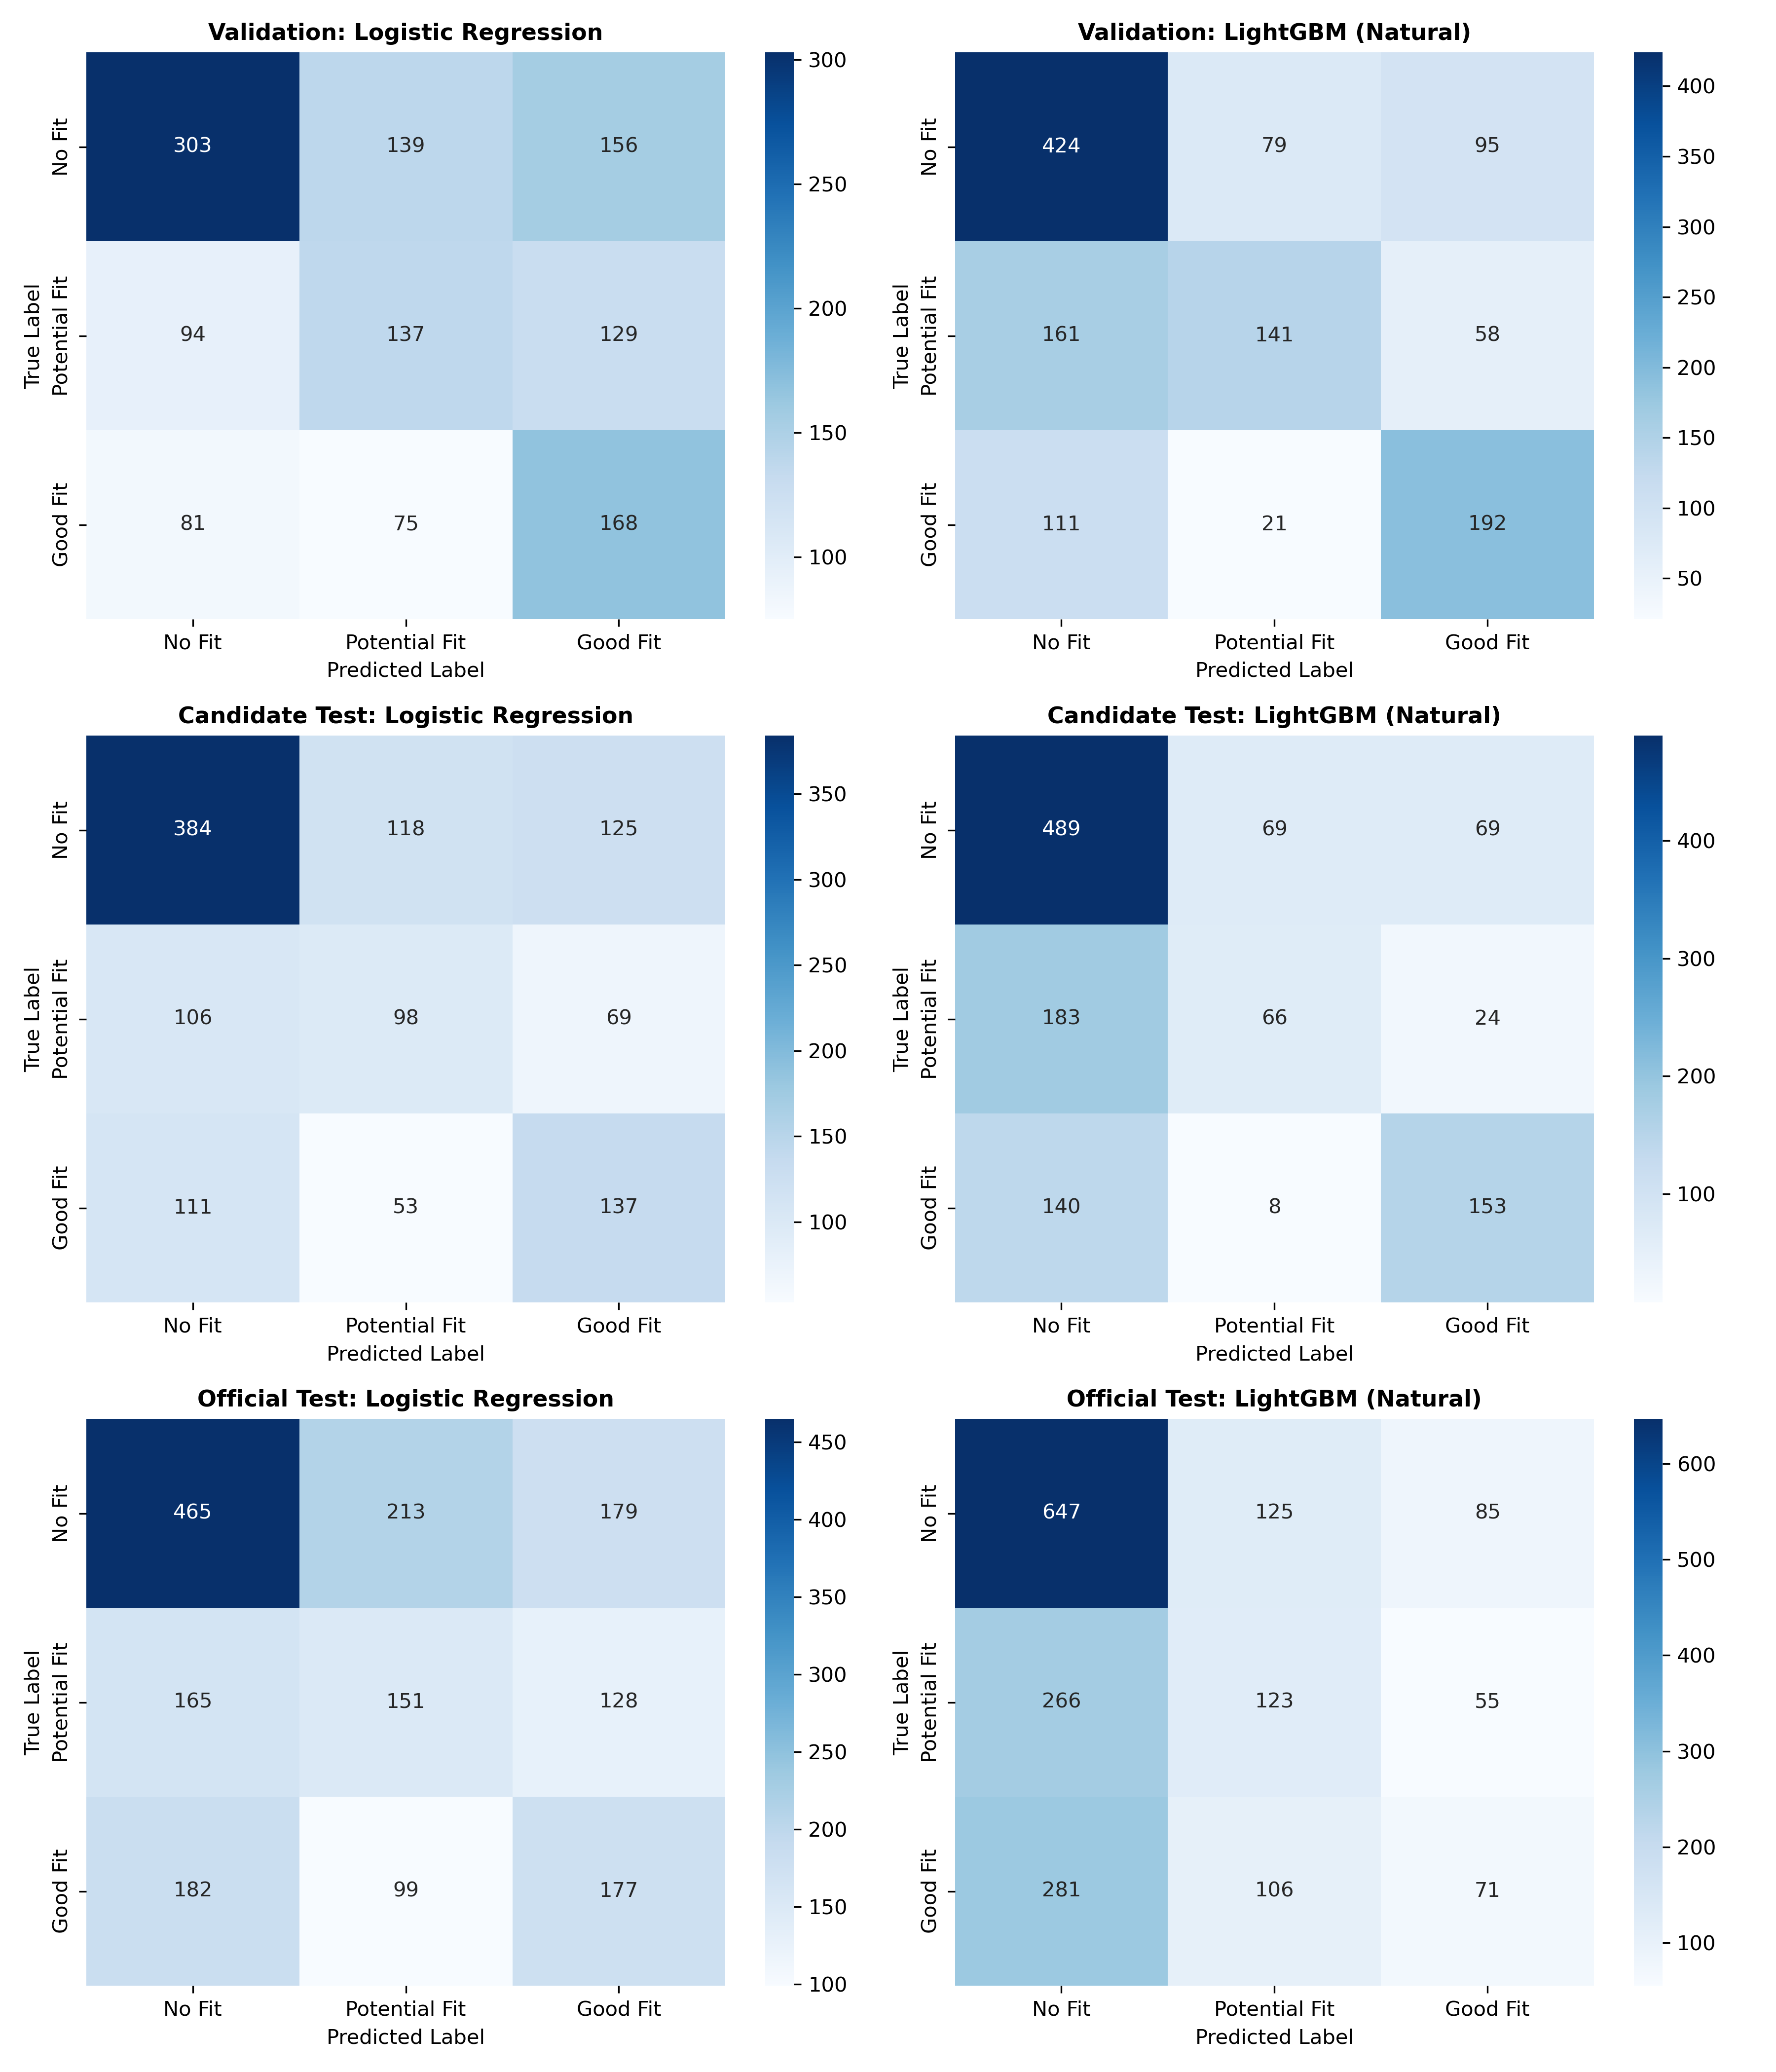

In [5]:
display(Image(filename='../data/evaluation/plots/phase8_lightgbm_confusion_matrix.png'))


### 12. Feature Importance Analysis
We analyze LightGBM's gain-based and split-based feature importances and compare them with the linear coefficients from Logistic Regression.


=== Top 10 Features by LightGBM Gain Importance ===


,feature,lgbm_gain_importance,lgbm_split_importance,lgbm_gain_pct,lr_mean_abs_coef
0,job_unique_token_count,6942.495771,1197,13.126352,0.502898
1,tfidf_cosine_similarity,6373.225276,1076,12.050017,0.105491
2,job_word_count,5946.577644,1166,11.243344,0.146131
3,job_char_count,5530.296020,1013,10.456270,0.394110
4,sbert_cosine_similarity,5272.435422,1186,9.968726,0.142869
5,num_job_skills,3394.713327,727,6.418470,0.051153
6,resume_word_count,2563.941764,681,4.847709,0.058678
7,num_resume_skills,2436.295829,643,4.606366,0.019199
8,jaccard_similarity,2336.453186,726,4.417591,0.169988
9,resume_unique_token_count,2308.788005,672,4.365284,0.168002


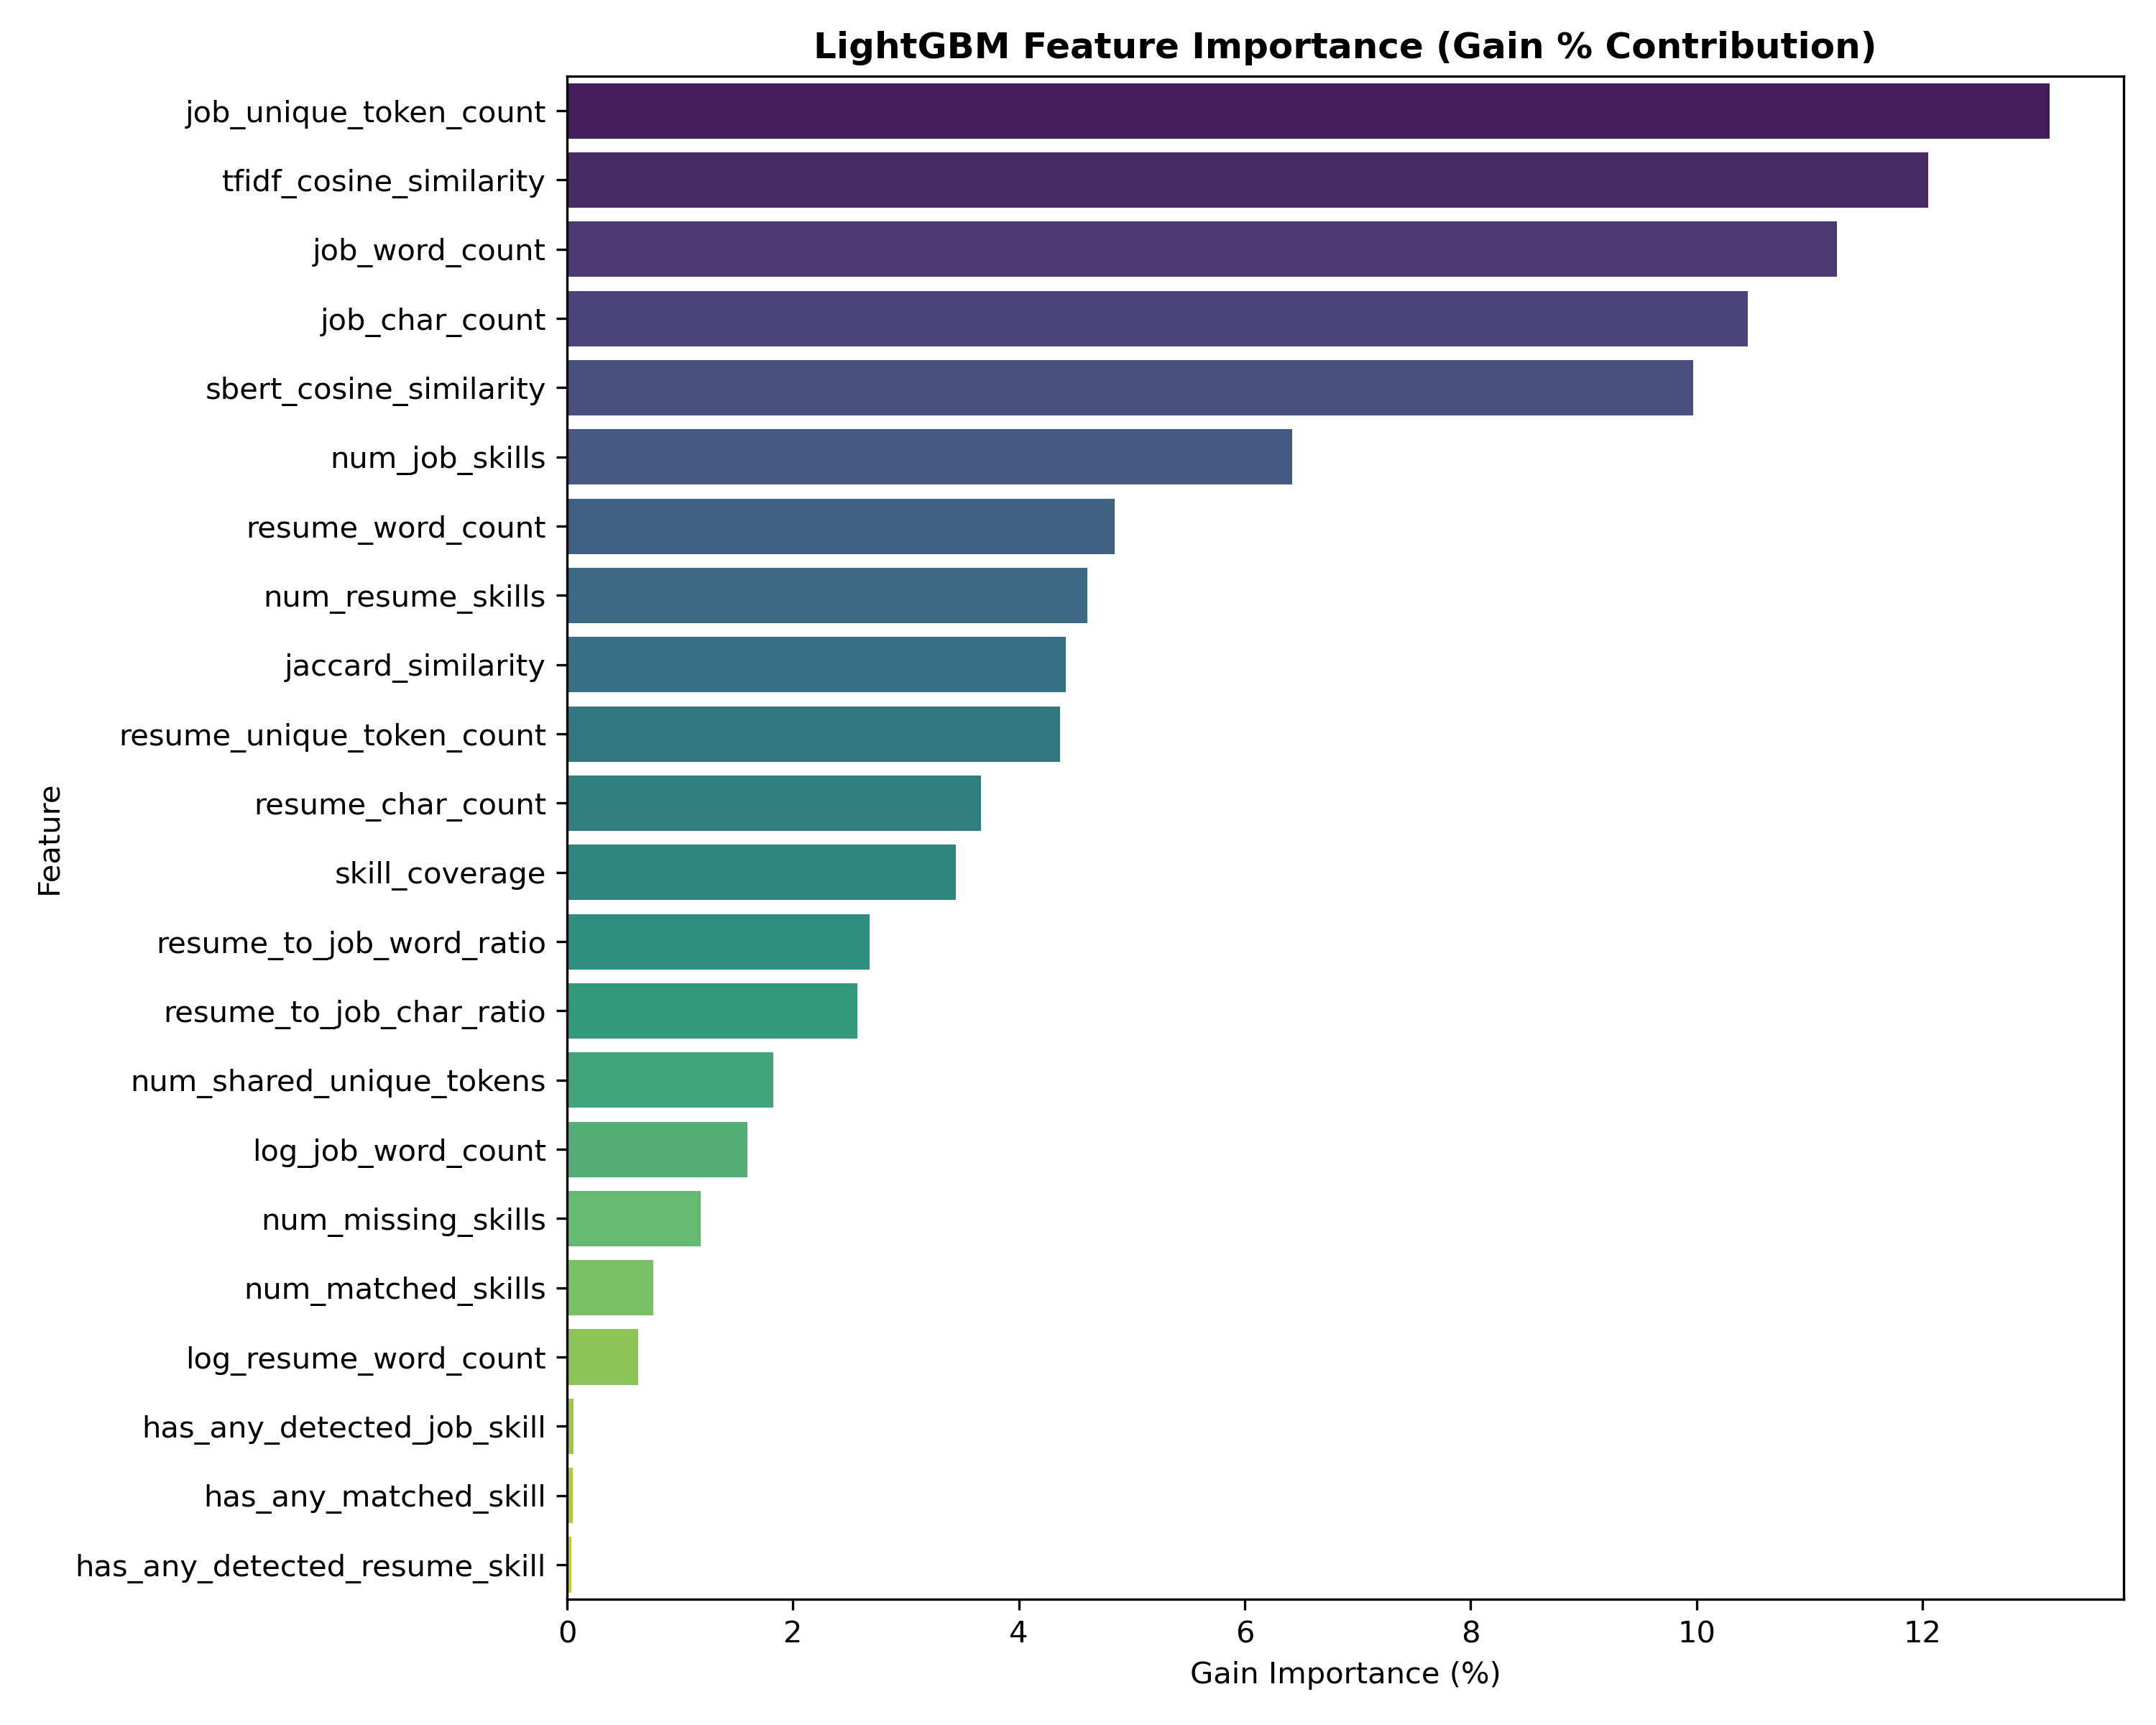

In [6]:
feat_imp_df = pd.read_csv('../data/evaluation/phase8_lightgbm_feature_importance.csv')
print("=== Top 10 Features by LightGBM Gain Importance ===")
display(feat_imp_df.head(10))

display(Image(filename='../data/evaluation/plots/phase8_lightgbm_feature_importance.png'))


### 13. Non-Linear Interaction Analysis
We evaluate four key feature pairings to see where decision boundaries benefit from non-linear thresholding:
1. SBERT Cosine Similarity × Jaccard Similarity
2. SBERT Cosine Similarity × Skill Coverage
3. TF-IDF Cosine Similarity × Skill Coverage
4. Skill Coverage × Resume-to-Job Word Ratio


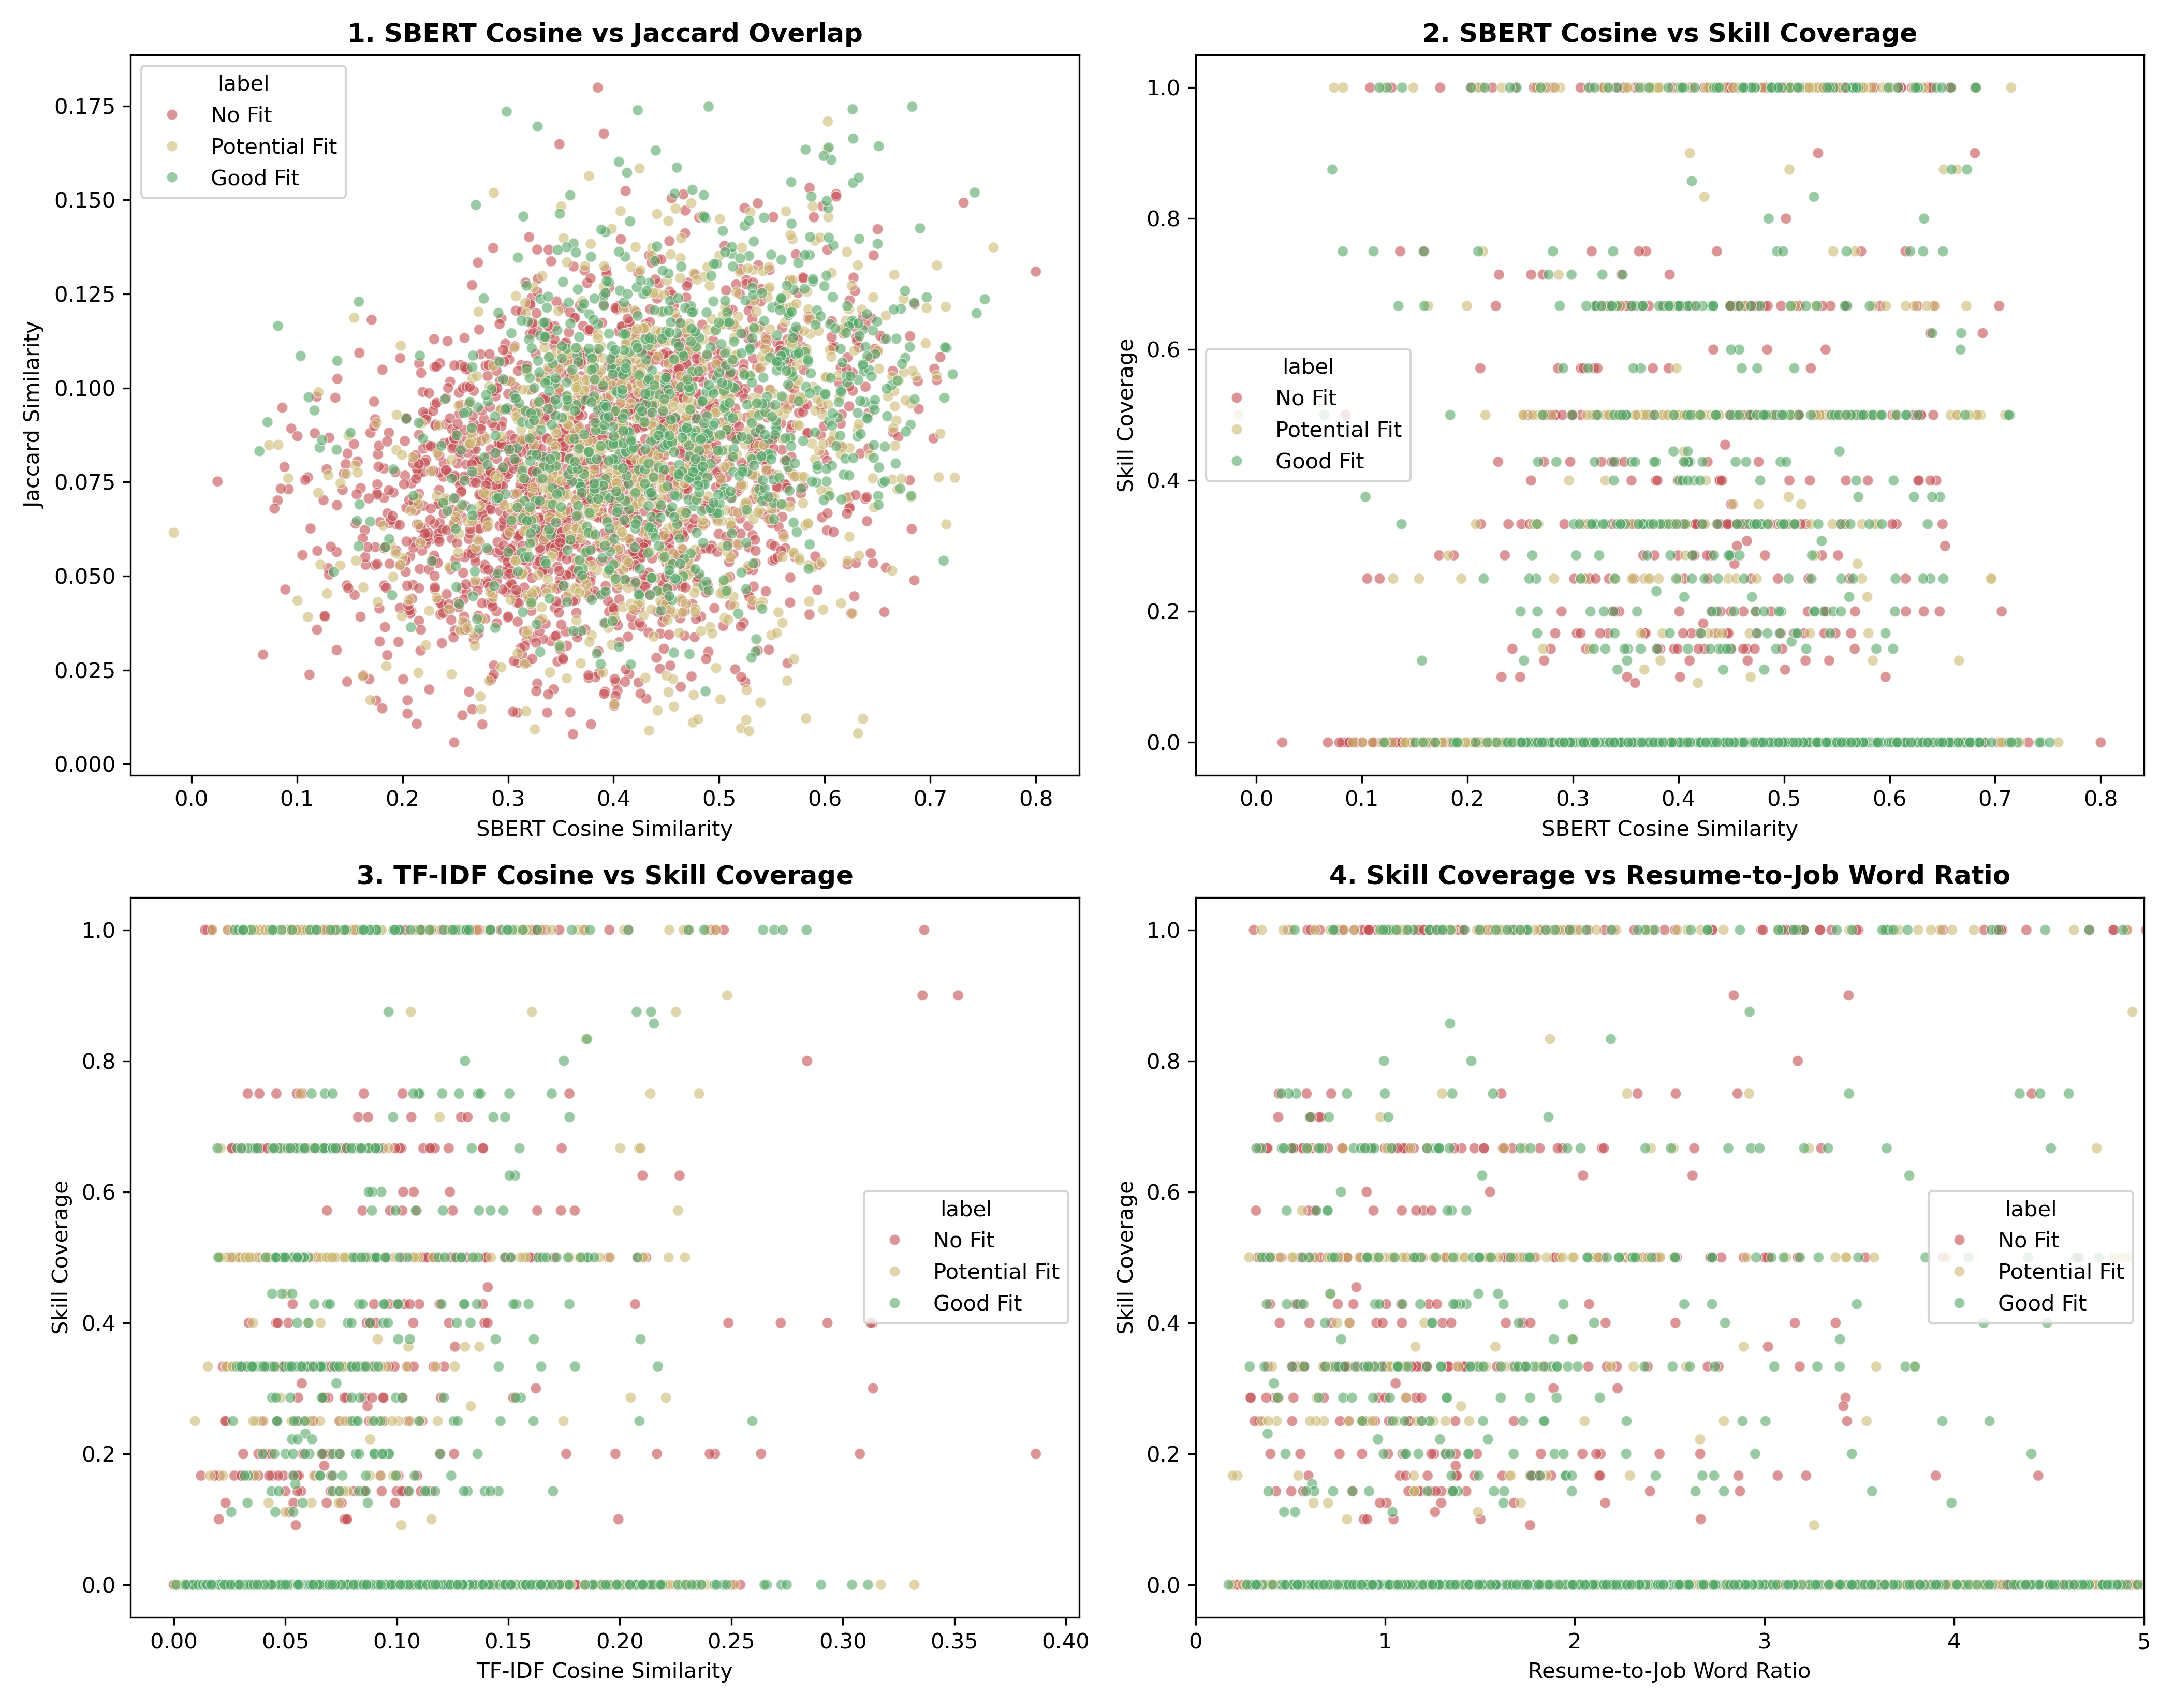

In [7]:
display(Image(filename='../data/evaluation/plots/phase8_lightgbm_interactions.png'))


### 14. Case-Level Transition Diagnostics (Logistic Regression vs LightGBM)
On `candidate_test` ($N=1,201$), LightGBM recovered **222 pairs** where Logistic Regression was wrong, while regressing on **133 pairs**, yielding a net accuracy gain of **+89 pairs (+7.41%)**.


In [8]:
rec_df = pd.read_csv('../data/evaluation/phase8_lightgbm_error_recovery.csv')

print("=== Error Recovery Transition Breakdown ===")
counts = rec_df['category'].value_counts()
display(counts)

print("\nSample Recovered Cases (LR Wrong -> LightGBM Correct):")
display(rec_df[rec_df['category'] == 'Recovered (LR wrong -> LGBM correct)'][['pair_id', 'true_label', 'pred_lr', 'pred_lgb', 'sbert_sim', 'tfidf_sim', 'skill_cov']].head(5))

print("\nSample Regressed Cases (LR Correct -> LightGBM Wrong):")
display(rec_df[rec_df['category'] == 'Regressed (LR correct -> LGBM wrong)'][['pair_id', 'true_label', 'pred_lr', 'pred_lgb', 'sbert_sim', 'tfidf_sim', 'skill_cov']].head(5))


=== Error Recovery Transition Breakdown ===


category
Recovered (LR wrong -> LGBM correct)    10
Regressed (LR correct -> LGBM wrong)    10
Both Wrong                              10
Name: count, dtype: int64


Sample Recovered Cases (LR Wrong -> LightGBM Correct):


,pair_id,true_label,pred_lr,pred_lgb,sbert_sim,tfidf_sim,skill_cov
0,3,No Fit,Potential Fit,No Fit,0.4072,0.0491,0.0
1,4,No Fit,Good Fit,No Fit,0.3864,0.1077,0.0
2,30,No Fit,Good Fit,No Fit,0.4133,0.0780,0.0
3,37,No Fit,Potential Fit,No Fit,0.5143,0.0217,0.0
4,39,No Fit,Potential Fit,No Fit,0.4528,0.0263,0.0



Sample Regressed Cases (LR Correct -> LightGBM Wrong):


,pair_id,true_label,pred_lr,pred_lgb,sbert_sim,tfidf_sim,skill_cov
10,11,No Fit,No Fit,Potential Fit,0.3659,0.0735,0.0000
11,130,No Fit,No Fit,Potential Fit,0.2429,0.0841,0.0000
12,148,No Fit,No Fit,Good Fit,0.3709,0.0326,0.0000
13,155,No Fit,No Fit,Good Fit,0.3757,0.0585,0.1667
14,159,No Fit,No Fit,Good Fit,0.3715,0.0474,0.0000


### 15. Computational Timing & Cost Benchmarks
We benchmark training time, prediction latency, and model size.


In [9]:
timing_df = pd.read_csv('../data/evaluation/phase8_lightgbm_timing.csv')
print("=== Computational Cost Comparison ===")
display(timing_df)


=== Computational Cost Comparison ===


,model,train_time_sec,pred_time_candidate_test_ms,latency_per_pair_ms,model_size_kb
0,Logistic Regression (Reference),0.0708,0.00,0.0000,2.54
1,LightGBM (Natural),0.7180,86.03,0.0203,1451.64


### 16, 17, 18. Strategic Interpretation & Recommendations

### Key Empirical Findings:
1. **Dramatic Lift on Unseen Candidates**:
   - **Validation Macro F1**: Rose from **0.4603** (LR) to **0.5662** (LightGBM) ($\mathbf{+0.1059}$).
   - **Candidate Test Macro F1**: Rose from **0.4735** (LR) to **0.5188** (LightGBM) ($\mathbf{+0.0453}$).
   - **Candidate Test Accuracy**: Jumped from **0.5154** to **0.5895** ($\mathbf{+7.41\%}$ absolute lift!).
   - **Good Fit Precision**: Surged from **41.39%** to **62.20%** ($\mathbf{+20.81\%}$).
   - **Good Fit Recall**: Increased from **45.51%** to **50.83%** ($\mathbf{+5.32\%}$).
   - **Good Fit F1**: Increased from **0.4335** to **0.5594** ($\mathbf{+12.59\%}$).

2. **Divergence on Unseen Job Descriptions (`official_test`)**:
   - Accuracy improved from **0.4508** to **0.4781** ($+2.73\%$), and `No Fit` F1 rose from **0.5572** to **0.6309**.
   - However, Macro F1 dropped from **0.4220** to **0.3838** ($-0.0382$) because `Good Fit` recall declined from 38.65% to 15.50%.
   - **Root Cause**: LightGBM relies heavily on specific length feature cutoffs (`job_unique_token_count`, `job_word_count`). When applied to entirely new job descriptions with different formatting and lengths, tree cutoffs become overly conservative.

3. **Classification Rule Outcome**:
   - Matches **OUTCOME B**: LightGBM heavily improves validation and candidate test, but exhibits generalization sensitivity on official test.
   - Documented in `DECISIONS.md` under **Decision 011: Non-Linear Gradient-Boosted Classification**.
